<!-- **Notes on Python virtual environment**

To activate the virtual environment, fix Windows bug then activate:
1. `Set-ExecutionPolicy Unrestricted -Scope Process`
2. `.venv\Scripts\activate` -->

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import networkx as nx
from algorithms import pgextra, fast_pgextra, gen_fast_pgextra
import pickle
from sklearn.datasets import load_svmlight_file

In [2]:
# Resolvent - soft thresholding operator
def soft_threshold(x, s):
    return np.sign(x) * np.clip(np.abs(x) - s, a_min=0, a_max=None) # Using numpy array operations

def JA(z, step, data):
    r"""
    Soft-thresholding operator: sgn(z[i])*max(abs(z[i])-\tau \lambda[i]), 0)
    """
    n = z.shape[0]
    JAz = np.zeros(z.shape)
    for ii in range(n):
        zi = z[ii].flatten()
        lambda_i = data['lambda'][ii]
        JAz[ii,:] = soft_threshold(zi, step*lambda_i)
    
    return JAz

def B(z, data):
    r"""
    Evaulate operator B(z) = [\grad_x fi(x, c); \grad_c fi(x,c)]
    """
    n = z.shape[0]
    mdims = data['m']
    Bz = np.zeros(z.shape)
    for ii in range(n):
        zi = z[ii].flatten()
        Abi = data['A'][ii]*data['b'][ii] # broadcast bi over columns of Ai
        
        pi = 1./(1+np.exp(-Abi@zi))
        Bz[ii,:] = (-1./mdims)*(Abi.T@(1-pi))
        
    return Bz

In [3]:
def residue_pg(x2, x1, K2, tW):
    r""" Distance between iterates, $||(q^k, x^k)-(q^{k-1}, x^{k-1})||^2_Q$ where Q=[[I, 0],[0, \tilde{W}]]
    :param: K2: K**2 = (I-W)/2
    :param: tW: = (I+W)/2
    """
    return np.vdot(x2, K2@x2) + np.vdot(x2 - x1, tW@(x2-x1))

def relerror_pg(x2, u1, q1, y1, step, tW, K2):
    """
    :param: x2: x^{k+1}
    :param: u1: u^{k}
    :param: q1: sum_{t=0}^k x^t
    :param: y1: B(x1)
    :param: tW: (I+W)/2
    :param: K2: K**2 = (I-W)/2
    """
    
    argument = step*y1 + u1 - x2 + K2@q1
    return  np.vdot(argument, tW@argument)

def consensus_pg(x2, K2):
    """
    :param: K2: K**2 = (I-W)/2
    """
    return np.vdot(x2, K2@x2)

def residue_fpg(z1, x1, tW, K2):
    r""" Distance between iterates, $||\bar{x}^{k} - x^k||^2_\tilde{W} + ||v^{k+1}||^2_{K^2}$ 
    np.vdot is the Frobenius inner product, which is the usual inner product on vectorised matrices
    :param: tW: = (I+W)/2
    :param: K2: = (I-W)/2 = I - tW
    """
    return np.vdot(z1 - x1, tW@(z1-x1)) + np.vdot(z1, K2@z1)

def relerror_fpg(z1, x1, tW):
    r""" Optimality error, $||\tau \nabla f(x^k) + \tau r^k + \tau Ky^k||^2_{(I+W)/2}$ where $r^k = (u^k-\bar{x}^k)/\tau$
    np.vdot is the Frobenius inner product, which is the usual inner product on vectorised matrices
    :param: tW: = (I+W)/2
    """
    return np.vdot(x1-z1,tW@(x1-z1))

def consensus_fpg(z1, K2):
    """
    :param: K2: K**2 = (I-W)/2
    """
    return np.vdot(z1, K2@z1)

In [4]:
nagents = 10
dataset = 'colon'
Xdata, ydata = load_svmlight_file(r'C:\Users\TIMMSLF\OneDrive - The University of Melbourne\Documents\PhD\Code\Data_fast_pgextra\\'+f'{dataset}')
Xdata, ydata = Xdata[:200], ydata[:200]
mdim = Xdata.shape[0]
d, p = Xdata.shape[0]//nagents, Xdata.shape[1]
Amat, bvec = {}, {}

for ii in range(nagents):
    if ii==nagents-1:
        Amat[ii] = Xdata[ii*d:].toarray()
        bvec[ii] = np.expand_dims(ydata[ii*d:], 1)
    else:
        Amat[ii] = Xdata[ii*d:(ii+1)*d].toarray()
        bvec[ii] = np.expand_dims(ydata[ii*d:(ii+1)*d], 1)
        
datadict = {'A': Amat, 'b': bvec, 'lambda': 0.0005*np.ones(nagents), 'm': Xdata.shape[0]}
datadict['lambda'] = 0.025*np.ones(nagents)
# Acond = [np.linalg.cond(Amat[ii]) for ii in range(nagents)]
# print(Acond)

In [5]:
# Algorithm parameters
# Graph from PG-EXTRA
edges = [(0,1),(0,3),(0,4),(0,6),
         (1,6),
         (2,6),(2,8),
         (3,4),(3,6),(3,8),(3,9),
         (4,5),
         (5,8),(5,9),
         (6,7),(6,8),
         (7,9),
         (8,9)]
G = nx.Graph(edges)

# Lap = nx.laplacian_matrix(G).todense()  # Laplacian
# beta = 0.6 * np.max(np.linalg.eigvalsh(Lap))    # beta satisfies beta > lambda_max(Lap)/2
# W = np.eye(nagents) - Lap / beta

# Metropolis constant edge weight matrix
eps = 1.
W = np.zeros((nagents, nagents))
for i,j in edges:
    W[i,j] = 1./(max(G.degree[i], G.degree[j])+eps) # w_ij = 1/(max{d_i, d_j}+\eps) for i,j\in Edges
    W[j, i] = W[i,j]
for i in range(nagents):
    W[i,i] = 1. - np.sum(W[i,:])    # w_ii = 1 - \sum_{j\in Edges} w_ij

L = 0.25/mdim*np.max([np.linalg.svdvals(Amat[ii])[0]**2 for ii in range(nagents)])  # L = max_i L_i = max_i {(1/4m)|Mi^T @ Mi|}
tau = 0.9 * (1 + np.min(np.linalg.eigvalsh(W))) / L  # tau <= (1-||K||^2)/L
thetainv = 2. - tau*L/(1 + np.min(np.linalg.eigvalsh(W)))   # 1/averaged constant of Condat-Vu operator
s = 0.9* thetainv # 0 < s < (4\beta_M-1)/(2\beta_M)
alpha = 5.
maxit = 10000

def alpha_k(k):
    # Compute alpha(k) linearly increasing to 100*alpha0 at maxit/2 iterations
    # a0: Initial alpha
    # k: iteration number
    # M: max iterations
    if k<= (maxit//2):
        ak = alpha + 99*alpha*k/(maxit//2)
    else:
        ak = 100*alpha
    return ak

def sigma_k(k):
    return alpha_k(k)

In [ ]:
x0 = np.zeros((nagents, p))
zsol1, res_pg, rel_pg, con_pg = pgextra(x0, JA, B, W, tau, residue_pg, relerror_pg, consensus_pg, max_iters=maxit, data=datadict)
print()
zsol2, res_gfpg500, rel_gfpg500, con_gfpg500 = gen_fast_pgextra(x0, JA, B, W, tau, lambda k: 500., s, lambda k: 500., 1.0, residue_fpg, relerror_fpg, consensus_fpg, max_iters=maxit, data=datadict)
print('')

etas = [0.1, 0.5, 0.8, 0.95, 1.0] # np.linspace(0.5, 1., num_params)
num_params = len(etas)

res_gfpg = np.zeros((num_params, maxit))
rel_gfpg = np.zeros((num_params, maxit))
con_gfpg = np.zeros((num_params, maxit))

# Run algorithms for different etas
for ii in range(num_params):
    print(f'\neta={etas[ii]:.2f}',end='\n')
    _, res_gfpg[ii,:], rel_gfpg[ii,:], con_gfpg[ii,:] = gen_fast_pgextra(x0, JA, B, W, tau, alpha_k, s, sigma_k, etas[ii], residue_fpg, relerror_fpg, consensus_fpg, max_iters=maxit, data=datadict)
print('')

# # Run algorithms for different alphas
# alphas = np.array([5., 10., 30., 100., 500., 5000.])
# for ii in range(num_params):
#     print(f'\nalpha={alphas[ii]}',end='\n')
#     zsol2, res_fpg[ii,:], rel_fpg[ii,:], con_fpg[ii,:] = fast_pgextra(x0, JA, B, W, tau, alphas[ii], s, residue_fpg, relerror_fpg, consensus_fpg, max_iters=maxit, data=datadict)
# print('')


# # Run algorithms for different s values
# ss = np.array([0.5, 0.75, 1., 1.25, 1.5, 1.75, 1.8, 1.9])
# for ii in range(num_params):
#     print(f'\ns={ss[ii]}',end='\n')
#     zsol2, res_fpg[ii,:], rel_fpg[ii,:], con_fpg[ii,:] = fast_pgextra(x0, JA, B, W, tau, alpha, ss[ii], rho, residue_fpg, relerror_fpg, consensus_fpg, max_iters=maxit, data=datadict)
# print('')


PG-EXTRA: iteration 10000 of 10000


TypeError: relerror_fpg() takes 3 positional arguments but 5 were given

In [ ]:
print(f'10% of {p}: {0.1*p}')
print(np.mean([np.sum(np.abs(zsol1[ii])>1e-10) for ii in range(nagents)]))

10% of 2000: 200.0
19.7


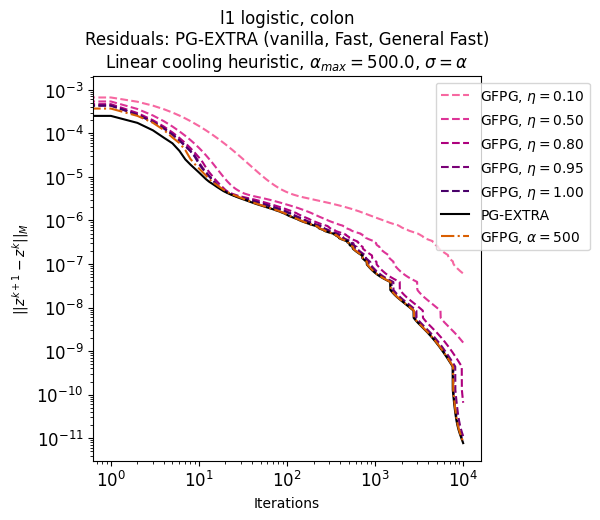

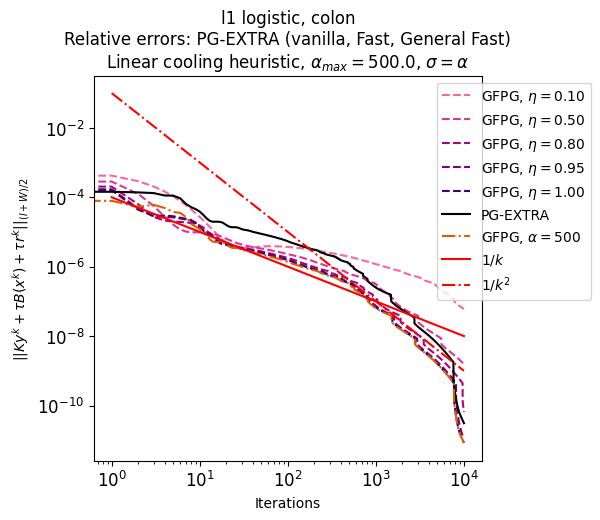

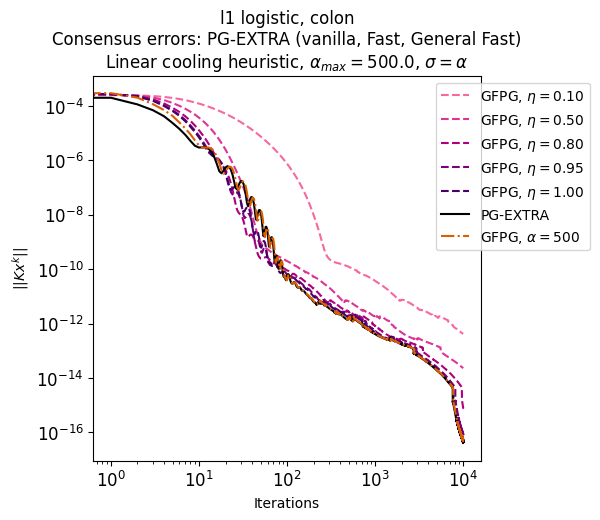

In [ ]:
colour = {'pg': 'k', 'fpg': '#d95f02', '500': '#d95f02', 0: '#f768a1', 1: '#dd3497', 2: '#ae017e', 3: '#7a0177', 4: '#49006a'}

# plasma = mpl.colormaps['plasma'].resampled(num_params)
# colour = {ii: plasma(ii) for ii in range(num_params)}
# colour['pg'] = 'k'
# colour['fpg']= 'r'

fig_res = plt.figure(figsize=(5, 5))
ax_res = fig_res.add_subplot(111)
scale_k = 1e-2
for ii in range(num_params):
    ax_res.semilogy(res_gfpg[ii], color=colour[ii], linestyle='--', label=r'GFPG, $\eta=$'+f'{etas[ii]:.2f}')
ax_res.semilogy(res_pg, color=colour['pg'], linestyle='-', label='PG-EXTRA')
ax_res.semilogy(res_gfpg500, color=colour['500'], linestyle='-.', label=r'GFPG, $\alpha=500$')
# ax_res.semilogy(res_fpg, color=colour['fpg'], linestyle='-.', label=r'FPG') # Fast PG-EXTRA (non-generalised)
ax_res.set_xlabel("Iterations")
ax_res.set_ylabel("$||z^{k+1}-z^k||_M$")
ax_res.set_title(f"l1 logistic, {dataset}\nResiduals: PG-EXTRA (vanilla, Fast, General Fast)\nLinear cooling heuristic, "+r"$\alpha_{max}=$"+f"{100*alpha}, "+r"$\sigma=\alpha$")
ax_res.tick_params(axis='both', which='both', labelsize=12)
ax_res.legend(loc='upper right', bbox_to_anchor=(1.3, 1))

scale_k = 1e-5
fig_rel = plt.figure(figsize=(5, 5))
ax_rel = fig_rel.add_subplot(111)
for ii in range(num_params):
    ax_rel.semilogy(rel_gfpg[ii], color=colour[ii], linestyle='--', label=r'GFPG, $\eta=$'+f'{etas[ii]:.2f}')
ax_rel.semilogy(rel_pg, color=colour['pg'], linestyle='-', label='PG-EXTRA')
ax_rel.semilogy(rel_gfpg500, color=colour['500'], linestyle='-.', label=r'GFPG, $\alpha=500$')
ax_rel.semilogy(np.arange(1, maxit), 1e-4/np.arange(1, maxit), color='r', linestyle='-', label='$1/k$')
ax_rel.semilogy(np.arange(1, maxit), 1e-1/np.arange(1, maxit)**2, color='r', linestyle='-.', label='$1/k^2$')
ax_rel.set_xlabel("Iterations")
ax_rel.set_ylabel(r"$||Ky^k + \tau B(x^k)+\tau r^k||_{(I+W)/2}$")
ax_rel.set_title(f"l1 logistic, {dataset}\nRelative errors: PG-EXTRA (vanilla, Fast, General Fast)\nLinear cooling heuristic, "+r"$\alpha_{max}=$"+f"{100*alpha}, "+r"$\sigma=\alpha$")
ax_rel.tick_params(axis='both', which='both', labelsize=12)
ax_rel.legend(loc='upper right', bbox_to_anchor=(1.3, 1))

scale_k = 1e-2
scale_k2 = 1e-2
fig_con = plt.figure(figsize=(5, 5))
ax_con = fig_con.add_subplot(111)
for ii in range(num_params):
    ax_con.semilogy(con_gfpg[ii], color=colour[ii], linestyle='--', label=r'GFPG, $\eta=$'+f'{etas[ii]:.2f}')
ax_con.semilogy(con_pg, color=colour['pg'], linestyle='-', label='PG-EXTRA')
ax_con.semilogy(con_gfpg500, color=colour['500'], linestyle='-.', label=r'GFPG, $\alpha=500$')
# ax_con.semilogy(con_fpg, color=colour['fpg'], linestyle='-.', label=r'FPG') # Fast PG-EXTRA (non-generalised)
ax_con.set_xlabel("Iterations")
ax_con.set_ylabel(r"$||Kx^k||$")
ax_con.set_title(f"l1 logistic, {dataset}\nConsensus errors: PG-EXTRA (vanilla, Fast, General Fast)\nLinear cooling heuristic, "+r"$\alpha_{max}=$"+f"{100*alpha}, "+r"$\sigma=\alpha$")
ax_con.tick_params(axis='both', which='both', labelsize=12)
ax_con.legend(loc='upper right', bbox_to_anchor=(1.3, 1))

# filepath = r'C:\\Users\\TIMMSLF\\OneDrive - The University of Melbourne\\Documents\\PhD\\Code\\'
# fig_res.savefig(f'{filepath}\\Plots\\Fast_pgextra\\fast_pgextra_logistic_res.pdf', bbox_inches='tight', pad_inches=0.2)
# fig_rel.savefig(f'{filepath}\\Plots\\Fast_pgextra\\fast_pgextra_logistic_rel.pdf', bbox_inches='tight', pad_inches=0.2)
# fig_con.savefig(f'{filepath}\\Plots\\Fast_pgextra\\fast_pgextra_logistic_con.pdf', bbox_inches='tight', pad_inches=0.2)